# DSCI 552 - Homework 5

- **Name:** Jesse Fulcher
- **GitHub Username:** jfulch
- **USC ID:** 7451-9585-45

## Decision Trees as Interpretable Models

### 1(a) - Download the Accute Inflamations data from https://archive.ics.uci.edu/ml/datasets/Acute+Inflammations.

In [22]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/diagnosis.data")

columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "burning_of_urethra",
    "bladder_inflammation",
    "nephritis"
]

acute_df = pd.read_csv(
    data_path,
    sep="\t",
    encoding="utf-16",
    decimal=",",
    header=None,
    names=columns
)

display(acute_df.head())
print(f"Dataset shape: {acute_df.shape}")
print(f"Missing values: {acute_df.isna().sum().sum()}")

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_of_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


Dataset shape: (120, 8)
Missing values: 0


### 1(b) - Build a decision tree on the whole data set and plot it.

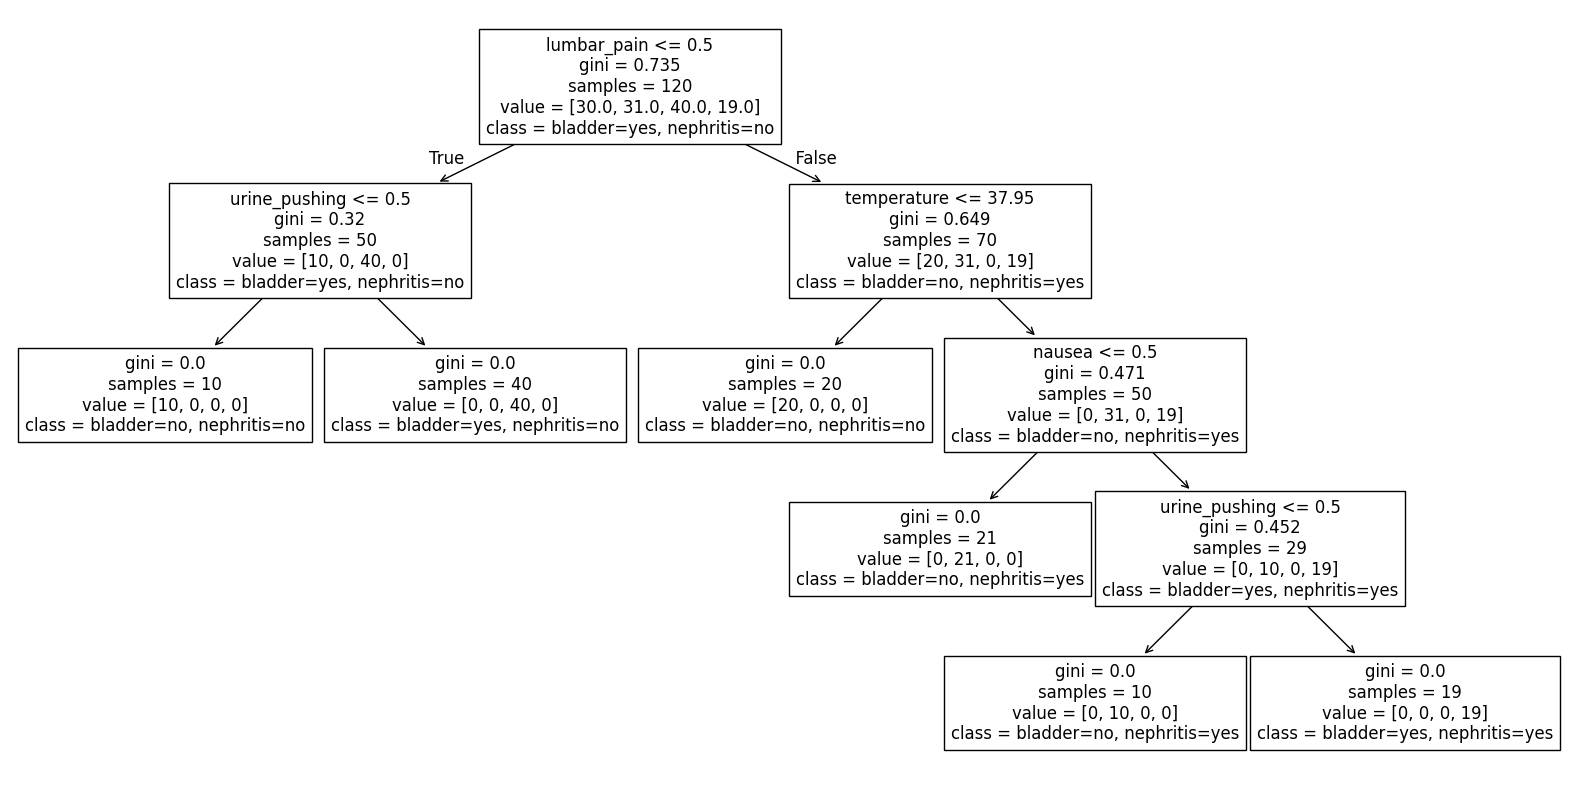

In [8]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

x = acute_df.iloc[:, :6].copy()

for column in x.columns[1:]:
    x[column] = x[column].map({"yes": 1, "no": 0})

y = (
    "bladder=" + acute_df["bladder_inflammation"].astype(str) + ", nephritis=" + acute_df["nephritis"].astype(str)
)

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(x, y)

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model, 
    feature_names=x.columns,
    class_names=tree_model.classes_.tolist()
)
plt.show()

### 1(c) - Convert the decision rules into a set of IF-THEN rules.

In [11]:
def get_if_then_rules(model, feature_names):
    tree_ = model.tree_
    rules = []

    def walk(node, conditions):
        left = tree_.children_left[node]
        right = tree_.children_right[node]

        if left == right:
            class_index = tree_.value[node][0].argmax()
            prediction = model.classes_[class_index]
            conditions_str = " AND ".join(conditions) if conditions else "TRUE"
            rules.append(f"IF {conditions_str} THEN {prediction}")
            return
        
        feature = feature_names[tree_.feature[node]]
        threshold = tree_.threshold[node]

        walk(left, conditions + [f"{feature} <= {threshold}"])
        walk(right, conditions + [f"{feature} > {threshold}"])

    walk(0, [])
    return rules

rules = get_if_then_rules(tree_model, x.columns.tolist())

for number, rule in enumerate(rules, start=1):
    print(f"{number}. {rule}")


1. IF lumbar_pain <= 0.5 AND urine_pushing <= 0.5 THEN bladder=no, nephritis=no
2. IF lumbar_pain <= 0.5 AND urine_pushing > 0.5 THEN bladder=yes, nephritis=no
3. IF lumbar_pain > 0.5 AND temperature <= 37.95000076293945 THEN bladder=no, nephritis=no
4. IF lumbar_pain > 0.5 AND temperature > 37.95000076293945 AND nausea <= 0.5 THEN bladder=no, nephritis=yes
5. IF lumbar_pain > 0.5 AND temperature > 37.95000076293945 AND nausea > 0.5 AND urine_pushing <= 0.5 THEN bladder=no, nephritis=yes
6. IF lumbar_pain > 0.5 AND temperature > 37.95000076293945 AND nausea > 0.5 AND urine_pushing > 0.5 THEN bladder=yes, nephritis=yes


### 1(d) - Use cost-complexity pruning to find a minimal decision tree and a set of decision rules with high interpretability

In [14]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score

path = tree_model.cost_complexity_pruning_path(x, y)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for alpha in np.unique(path.ccp_alphas):
    model = DecisionTreeClassifier(
        ccp_alpha=float(alpha),
        random_state=42
    )

    scores = cross_val_score(
        model, x, 
        y, 
        cv=cv,
        scoring="accuracy"
    )

    model.fit(x, y)

    results.append({
        "alpha": float(alpha),
        "mean_cv_accuracy": scores.mean(),
        "standard_error": scores.std(ddof=1) / np.sqrt(len(scores)),
        "leaves": model.get_n_leaves(),
        "depth": model.get_depth()
    })

pruning_results = pd.DataFrame(results)

best_index = pruning_results["mean_cv_accuracy"].idxmax()
best_result = pruning_results.loc[best_index]

cutoff = (
    best_result["mean_cv_accuracy"] - best_result["standard_error"]
)

eligible = pruning_results[
    pruning_results["mean_cv_accuracy"] >= cutoff
]

selected = eligible.sort_values(
    by=["leaves","alpha"]
).iloc[0]

selected_alpha = float(selected["alpha"])

display(pruning_results)
print(f"Selected alpha: {selected_alpha:.6f}")
print(f"Selected mean CV accuracy: {selected['mean_cv_accuracy']:.3f}")

,alpha,mean_cv_accuracy,standard_error,leaves,depth
0,0.000000,0.991667,0.008333,6,4
1,0.098167,0.858333,0.025000,4,2
2,0.133333,0.758333,0.033333,3,2
3,0.182000,0.666667,0.029463,2,1
4,0.222917,0.483333,0.061237,1,0


Selected alpha: 0.000000
Selected mean CV accuracy: 0.992


Original tree: depth=4, leaves=6
Selected tree: depth=4, leaves=6


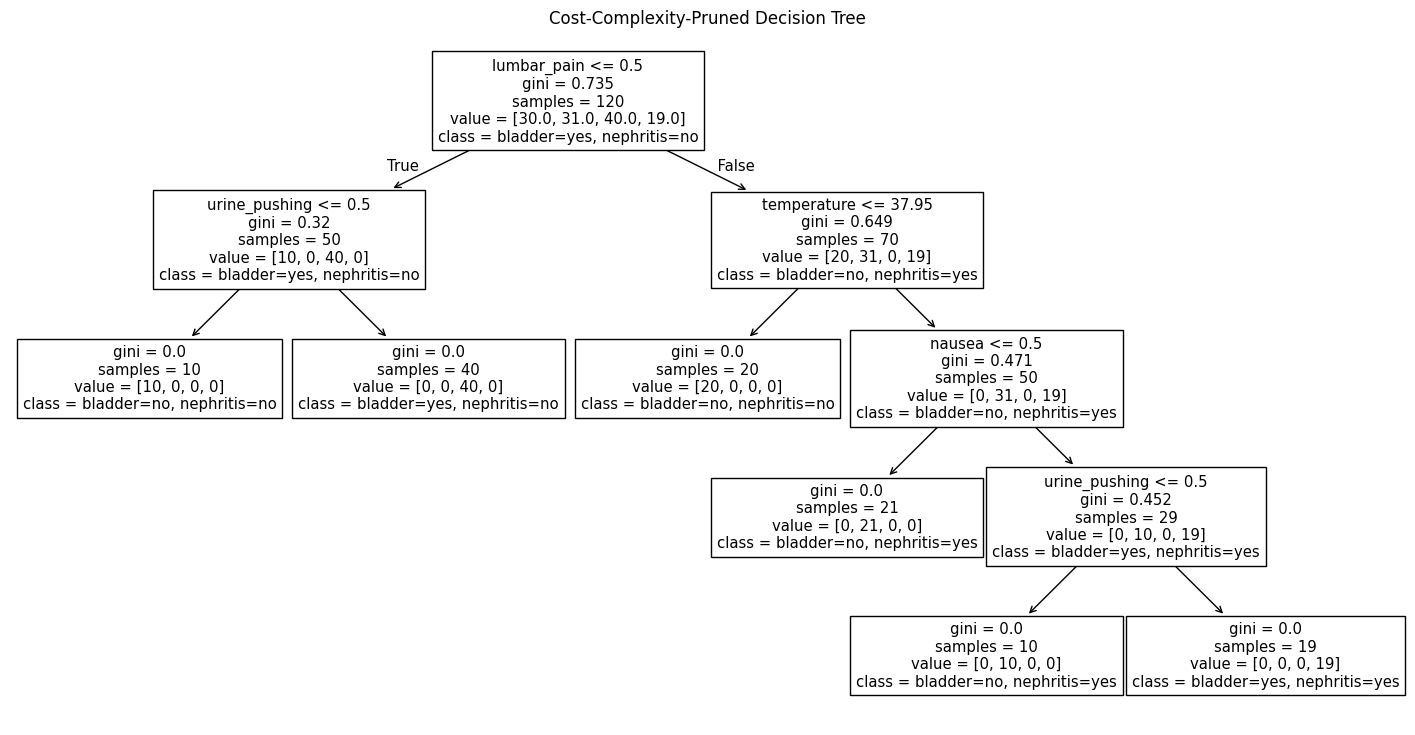

In [19]:
pruned_tree = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=selected_alpha,
)

pruned_tree.fit(x, y)

print(
    f"Original tree: depth={tree_model.get_depth()}, "
    f"leaves={tree_model.get_n_leaves()}"
)
print(
    f"Selected tree: depth={pruned_tree.get_depth()}, "
    f"leaves={pruned_tree.get_n_leaves()}"
)

plt.figure(figsize=(18, 9))

plot_tree(
    pruned_tree,
    feature_names=x.columns.tolist(),
    class_names=pruned_tree.classes_.tolist()
)

plt.title("Cost-Complexity-Pruned Decision Tree")
plt.show()

## 2. The LASSO and Boosting for Regression


### 2(a) - Download the Communities and Crime data3 from https://archive.ics.uci. edu/ml/datasets/Communities+and+Crime. Use the first 1495 rows of data as the training set and the rest as the test set.

In [28]:
communities_df = pd.read_csv("../data/communities.data", header=None, na_values="?")

train_df = communities_df.iloc[:1495].copy()
test_df = communities_df.iloc[1495:].copy()

### 2(b) - The data set has missing values. Use a data imputation technique to deal with the missing values in the data set. The data description mentions some features are nonpredictive. Ignore those features

In [30]:
from sklearn.impute import SimpleImputer

x_train = train_df.iloc[:, 5:-1].copy()
x_test = test_df.iloc[:, 5:-1].copy()

y_train = train_df.iloc[:, -1].copy()
y_test = test_df.iloc[:, -1].copy()

imputer = SimpleImputer(strategy="median", keep_empty_features=True)

x_train = pd.DataFrame(
    imputer.fit_transform(x_train),
    columns=x_train.columns,
    index=x_train.index,
)

x_test = pd.DataFrame(
    imputer.transform(x_test),
    columns=x_test.columns,
    index=x_test.index,
)